In [4]:
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import resample_poly


In [5]:
def normalize_audio(audio):
    peak = np.max(np.abs(audio))
    return audio if peak == 0 else audio / peak


def load_audio(filepath):
    audio, sample_rate = sf.read(filepath)

    # Convert stereo audio to mono
    if audio.ndim >= 2:
        audio = audio.mean(axis=1)

    return normalize_audio(audio), sample_rate


def match_sample_rate(audio1, sample_rate1, audio2, sample_rate2):
    sample_rate = min(sample_rate1, sample_rate2)

    if sample_rate1 != sample_rate:
        audio1 = resample_poly(audio1, sample_rate, sample_rate1)

    if sample_rate2 != sample_rate:
        audio2 = resample_poly(audio2, sample_rate, sample_rate2)

    return audio1, audio2, sample_rate


In [6]:
gunshot, gunshot_sr = load_audio("Rizwan_BSAI23004_gunshot.mp3")
recording, recording_sr = load_audio("Rizwan_BSAI23004_sample.mp3")

gunshot, recording, sample_rate = match_sample_rate(
    gunshot, gunshot_sr, recording, recording_sr
)

print(f"Sample rate: {sample_rate} Hz")
print(f"Speech samples: {len(recording)}")
print(f"Impulse response samples: {len(gunshot)}")


Sample rate: 48000 Hz
Speech samples: 134784
Impulse response samples: 147456


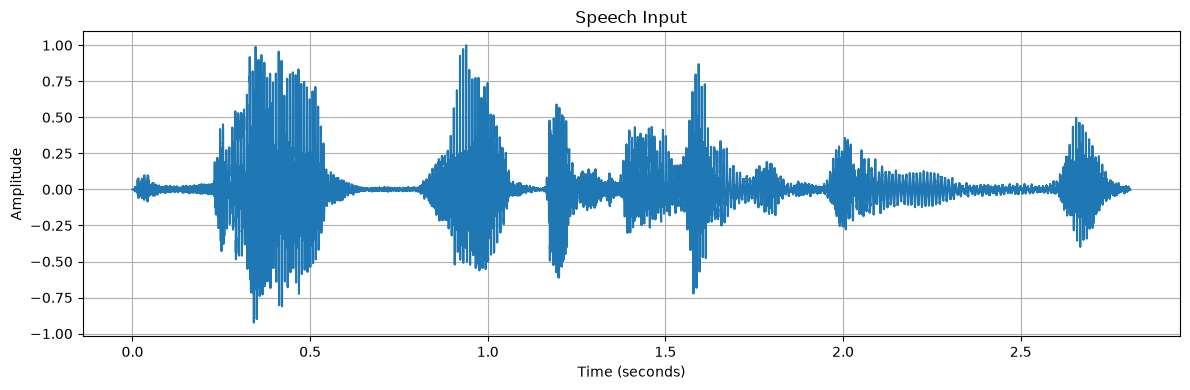

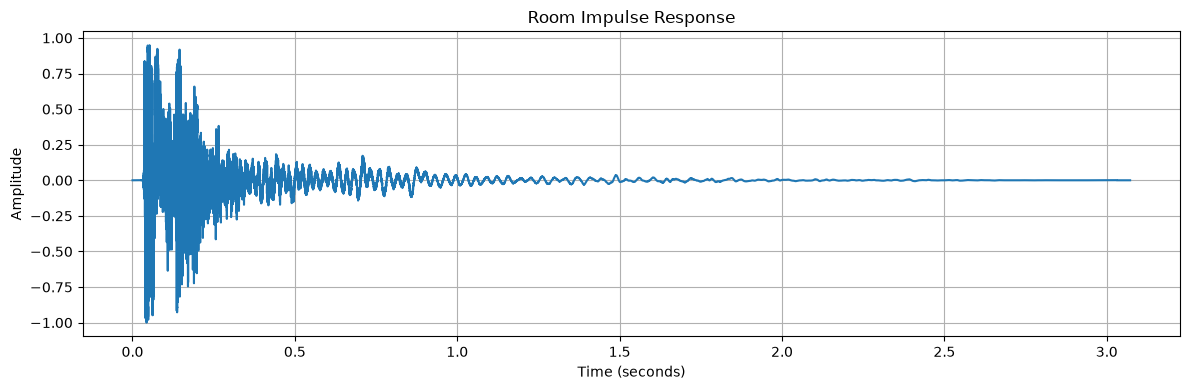

In [7]:
speech_time = np.arange(len(recording)) / sample_rate
ir_time = np.arange(len(gunshot)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(speech_time, recording)
plt.title("Speech Input")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.tight_layout()
plt.savefig("Rizwan_BSAI23004_speech_input.png", dpi=300)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(ir_time, gunshot)
plt.title("Room Impulse Response")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.tight_layout()
plt.savefig("Rizwan_BSAI23004_room_impulse_response.png", dpi=300)
plt.show()


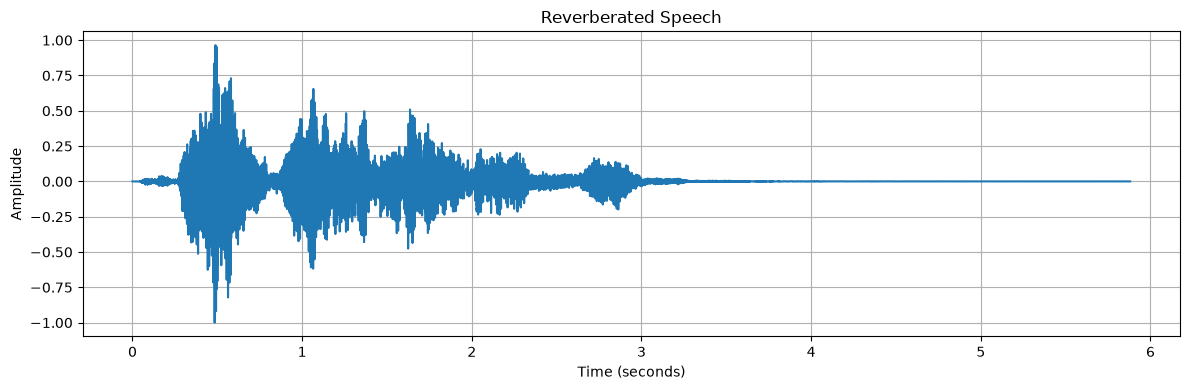

In [8]:
# Convolution gives the speech after passing through the room
output = np.convolve(recording, gunshot, mode="full")
output = normalize_audio(output)

sf.write("Rizwan_BSAI23004_reverberated_speech.wav", output, sample_rate)

output_time = np.arange(len(output)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(output_time, output)
plt.title("Reverberated Speech")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.tight_layout()
plt.savefig("Rizwan_BSAI23004_reverberated_speech.png", dpi=300)
plt.show()


In [9]:
k = 0
k1 = 100_000
k2 = 200_000

# Put three impulses far enough apart to hear separate echoes
synthetic_ir = np.zeros(k2 + 1)
synthetic_ir[k] = 3
synthetic_ir[k1] = 2
synthetic_ir[k2] = 1

synthetic_ir = normalize_audio(synthetic_ir)

print("Impulse values:", synthetic_ir[k], synthetic_ir[k1], synthetic_ir[k2])


Impulse values: 1.0 0.6666666666666666 0.3333333333333333


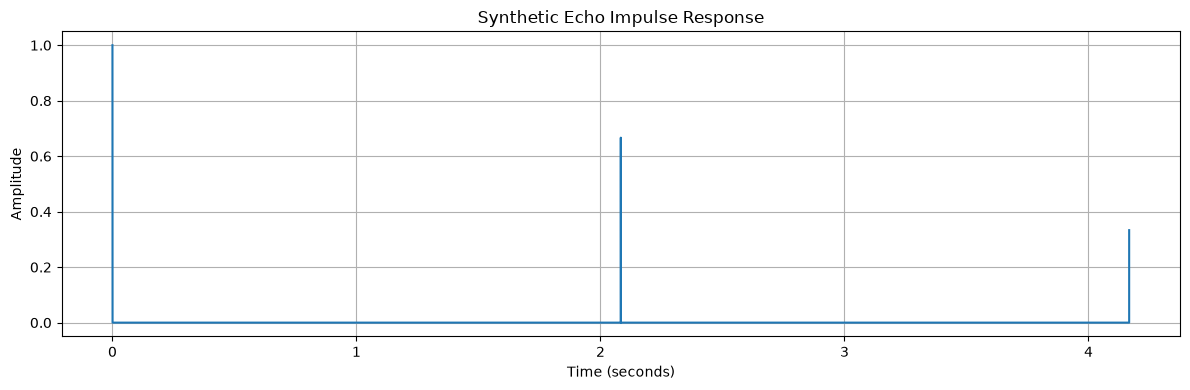

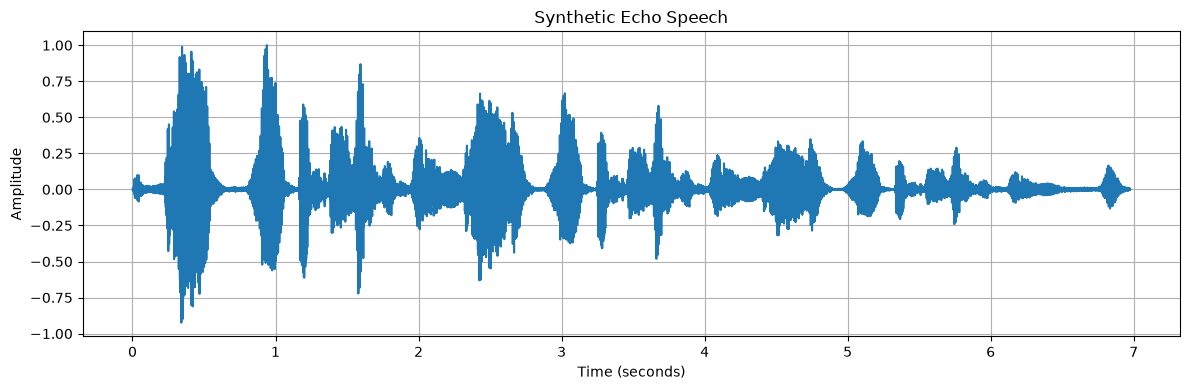

In [10]:
synthetic_time = np.arange(len(synthetic_ir)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(synthetic_time, synthetic_ir)
plt.title("Synthetic Echo Impulse Response")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.tight_layout()
plt.savefig("Rizwan_BSAI23004_synthetic_echo_impulse_response.png", dpi=300)
plt.show()

synthetic_output = np.convolve(
    recording, synthetic_ir, mode="full"
)
synthetic_output = normalize_audio(synthetic_output)

sf.write(
    "Rizwan_BSAI23004_synthetic_echo_speech.wav",
    synthetic_output,
    sample_rate
)

synthetic_output_time = np.arange(len(synthetic_output)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(synthetic_output_time, synthetic_output)
plt.title("Synthetic Echo Speech")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.tight_layout()
plt.savefig("Rizwan_BSAI23004_synthetic_echo_speech.png", dpi=300)
plt.show()
